<a href="https://colab.research.google.com/github/1604056nizam/Rag-Models/blob/main/Adaptive_k.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

!pip install -q numpy sentence-transformers


In [3]:

import numpy as np
from sentence_transformers import SentenceTransformer


def find_adaptive_k(scores: list[float]) -> int:
    """
    Computes the cutoff k by detecting the knee/elbow point
    on the sorted similarity score curve.

    Inspired by Adaptive-k (Taguchi et al., EMNLP 2025).
    """

    n_points = len(scores)

    if n_points <= 1:
        return n_points

    # Create 2D coordinates: (rank_index, similarity_score)
    coords = np.vstack((
        np.arange(n_points),
        scores
    )).T

    first_pt = coords[0]
    last_pt = coords[-1]

    # Vector representing the secant line
    line_vec = last_pt - first_pt
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Calculate perpendicular distance from each score
    # point to the secant line
    vec_from_first = coords - first_pt

    scalar_proj = np.sum(
        vec_from_first * line_vec_norm,
        axis=1
    )

    vec_proj = np.outer(
        scalar_proj,
        line_vec_norm
    )

    perpendicular_vecs = vec_from_first - vec_proj

    distances = np.linalg.norm(
        perpendicular_vecs,
        axis=1
    )

    # Rank with maximum perpendicular distance
    optimal_k = int(np.argmax(distances) + 1)

    return optimal_k


In [4]:

class AdaptiveKRetriever:

    def __init__(
        self,
        model_name: str = "all-MiniLM-L6-v2"
    ):
        self.encoder = SentenceTransformer(model_name)
        self.documents = []
        self.doc_embeddings = None

    def index_documents(self, docs: list[str]):
        """
        Embed and index the document corpus.
        """
        self.documents = docs

        self.doc_embeddings = self.encoder.encode(
            docs,
            normalize_embeddings=True
        )

    def retrieve(
        self,
        query: str,
        max_candidates: int = 20
    ) -> dict:
        """
        Retrieve top-N candidate passages, calculate the
        adaptive cutoff, and return selected context.
        """

        if self.doc_embeddings is None:
            raise ValueError("Index documents before retrieval.")

        # Generate query embedding
        query_emb = self.encoder.encode(
            query,
            normalize_embeddings=True
        )

        # Calculate cosine similarity
        raw_scores = np.dot(
            self.doc_embeddings,
            query_emb
        )

        # Sort documents by similarity (highest first)
        top_indices = np.argsort(raw_scores)[::-1][
            :max_candidates
        ]

        candidate_scores = raw_scores[
            top_indices
        ].tolist()

        candidate_docs = [
            self.documents[i]
            for i in top_indices
        ]

        # Calculate dynamic cutoff
        k = find_adaptive_k(candidate_scores)

        return {
            "query": query,
            "optimal_k": k,
            "selected_docs": candidate_docs[:k],
            "selected_scores": candidate_scores[:k],
            "candidate_scores": candidate_scores,
        }


In [5]:

corpus = [
    (
        "STAIR uses Table of Contents as the unit of "
        "retrieval for long books."
    ),
    (
        "Adaptive-k dynamically selects context length "
        "based on similarity distribution."
    ),
    (
        "DSI relies on differentiable search indexes "
        "mapping queries directly to doc IDs."
    ),
    (
        "Python is a popular programming language widely "
        "used in AI and data science."
    ),
    (
        "Baking sourdough bread requires flour, water, "
        "salt, and wild yeast starters."
    ),
    (
        "Photosynthesis converts light energy into "
        "chemical energy in plant cells."
    ),
    (
        "The Eiffel Tower is located on the Champ de "
        "Mars in Paris, France."
    ),
    (
        "Quantum computing uses qubits to perform "
        "parallel state computations."
    ),
]

retriever = AdaptiveKRetriever()
retriever.index_documents(corpus)

print(f"Indexed {len(corpus)} documents successfully.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Indexed 8 documents successfully.


In [6]:

# Test 1: Specific query
res1 = retriever.retrieve(
    "How does Adaptive-k select context size?"
)

print("Query:", res1["query"])
print("Optimal k:", res1["optimal_k"])
print("Selected documents:")

for doc in res1["selected_docs"]:
    print("-", doc)

print("-" * 50)

# Test 2: Broader query
res2 = retriever.retrieve(
    "Tell me about retrieval models in artificial intelligence"
)

print("Query:", res2["query"])
print("Optimal k:", res2["optimal_k"])
print("Selected documents:")

for doc in res2["selected_docs"]:
    print("-", doc)


Query: How does Adaptive-k select context size?
Optimal k: 3
Selected documents:
- Adaptive-k dynamically selects context length based on similarity distribution.
- DSI relies on differentiable search indexes mapping queries directly to doc IDs.
- Quantum computing uses qubits to perform parallel state computations.
--------------------------------------------------
Query: Tell me about retrieval models in artificial intelligence
Optimal k: 3
Selected documents:
- DSI relies on differentiable search indexes mapping queries directly to doc IDs.
- Python is a popular programming language widely used in AI and data science.
- STAIR uses Table of Contents as the unit of retrieval for long books.


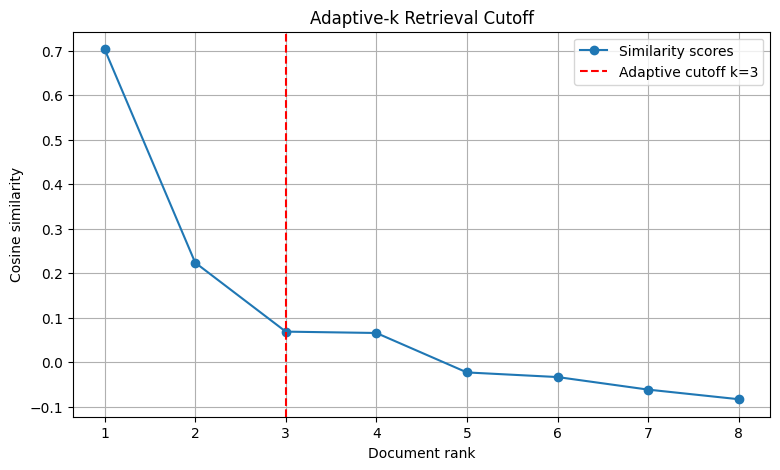

In [7]:

import matplotlib.pyplot as plt

scores = res1["candidate_scores"]
ranks = np.arange(1, len(scores) + 1)
k = res1["optimal_k"]

plt.figure(figsize=(9, 5))

plt.plot(
    ranks,
    scores,
    marker="o",
    label="Similarity scores"
)

plt.axvline(
    x=k,
    color="red",
    linestyle="--",
    label=f"Adaptive cutoff k={k}"
)

plt.xlabel("Document rank")
plt.ylabel("Cosine similarity")
plt.title("Adaptive-k Retrieval Cutoff")
plt.legend()
plt.grid(True)
plt.show()


In [8]:

query = "How does Adaptive-k select context size?"

result = retriever.retrieve(query, max_candidates=8)

scores = result["candidate_scores"]

print("Fixed top-3:", 3)
print("Fixed top-5:", 5)
print("Adaptive-k:", result["optimal_k"])

print("\nAll candidate scores:")

for i, score in enumerate(scores, start=1):
    print(f"Rank {i}: {score:.4f}")


Fixed top-3: 3
Fixed top-5: 5
Adaptive-k: 3

All candidate scores:
Rank 1: 0.7031
Rank 2: 0.2235
Rank 3: 0.0685
Rank 4: 0.0654
Rank 5: -0.0232
Rank 6: -0.0336
Rank 7: -0.0618
Rank 8: -0.0834
